<center>МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ </center>
<center>ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ ВЫСШЕГО ОБРАЗОВАНИЯ </center>
<center>«НОВОСИБИРСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНИЧЕСКИЙ УНИВЕРСИТЕТ»</center>
<center>Кафедра Вычислительной техники </center>
<br>
<center> <b> <font size="5">  ОТЧЁТ </font>  </b>  </center>   
<center><font size="3">по лабораторной работе №2</font></center>
<center><font size="3">по дисциплине: «Анализ временных рядов. Метод последовательной идентификации составляющих ВР» </font></center>
<br>

Выполнили:
- Клименко К.В.
- Бадагов А.В.

Преподаватель: Альсова О.К.

<center>  Новосибирск, 2026  </center>

# Цель работ

- Изучить методы и алгоритмы прогнозирования временных рядов на
примере решения конкретной задачи ИАД;
- Исследовать эффективность использования различных методов
прогнозирования временных рядов для решения прикладной задачи
- Ознакомиться и получить практические навыки работы с языком Python
для решения задач исследования и прогнозирования временных
рядов.


# Ход работы

In [ ]:
# Python 3.13.15
import pandas as pd
import numpy  as np

from statsmodels.tsa.seasonal import seasonal_decompose

from scipy.optimize import curve_fit
from scipy.signal import periodogram

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_ljungbox

%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import cm
import seaborn as sns

In [ ]:
df = pd.read_csv("./2.csv",
        sep=';',
        decimal='.',
        header=0,
        encoding='cp1251'
    )
df = df.iloc[:, :4]
display(df)

,год,месяц,t,вар 1
0,2010,1,1,15.000000
1,2010,2,2,16.359533
2,2010,3,3,29.629860
3,2010,4,4,31.585145
4,2010,5,5,33.019945
...,...,...,...,...
187,2025,8,188,171.316383
188,2025,9,189,173.912124
189,2025,10,190,173.025473
190,2025,11,191,168.093211


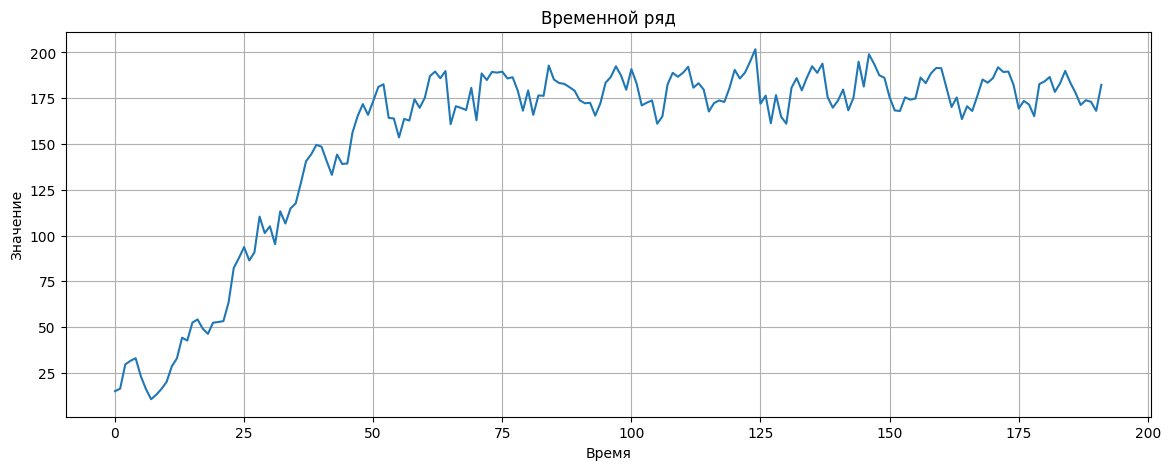

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(df['вар 1'])

plt.title('Временной ряд')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(True)

plt.show()

In [ ]:
period = 12

decomposition = seasonal_decompose(
    df['вар 1'],
    model='additive',
    period=period
)

trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

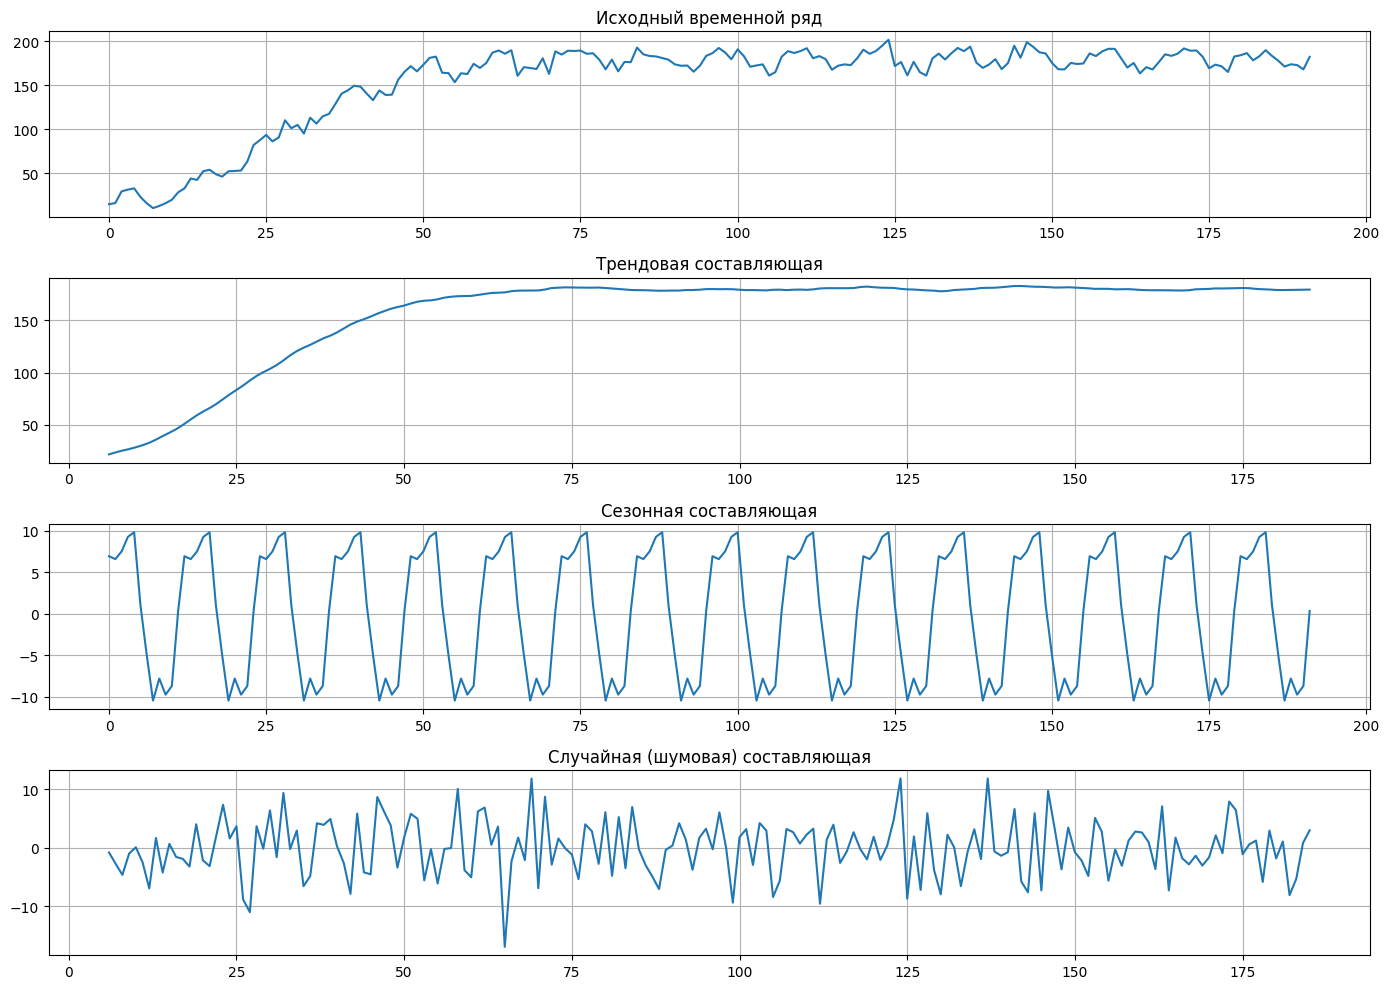

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10))

axes[0].plot(df['вар 1'])
axes[0].set_title('Исходный временной ряд')
axes[0].grid(True)

axes[1].plot(trend)
axes[1].set_title('Трендовая составляющая')
axes[1].grid(True)

axes[2].plot(seasonal)
axes[2].set_title('Сезонная составляющая')
axes[2].grid(True)

axes[3].plot(residual)
axes[3].set_title('Случайная (шумовая) составляющая')
axes[3].grid(True)

plt.tight_layout()
plt.show()

По графику исходного временного ряда и результатам декомпозиции видно наличие выраженной трендовой составляющей. В начале рассматриваемого периода уровень ряда возрастает от значений порядка 15–30 до уровня около 180. По мере роста скорость изменения ряда уменьшается, после чего происходит выход на практически постоянный уровень около 180–185. Следовательно, основная тенденция является нелинейной и имеет характер роста с насыщением. Вертикальные асимптоты отсутствуют; наблюдается верхняя горизонтальная асимптота. Тренд в целом является возрастающим, однако после достижения уровня насыщения становится практически горизонтальным.
Во временном ряду также присутствует выраженная сезонная составляющая. Сезонные колебания повторяются через каждые 12 наблюдений, что соответствует годовому периоду для представленных месячных данных. Значения сезонной составляющей изменяются приблизительно от \(-10\) до \(+10\), поэтому амплитуда составляет около 10 единиц, а полный размах — около 20 единиц.
Амплитуда сезонных колебаний с течением времени практически не изменяется и не увеличивается вместе с уровнем ряда.

№2.3.1
На основании визуального анализа в качестве структурной модели тренда выбрана логистическая кривая. Такой выбор обусловлен характером временного ряда: на начальном участке наблюдается рост, затем скорость роста уменьшается и значения выходят на практически постоянный уровень. Логистическая функция обладает верхней горизонтальной асимптотой и позволяет описать процесс роста с насыщением.
Для параметрической идентификации использована эквивалентная параметризация логистической функции

In [ ]:
def logistic(t, L, k, t0):
    return L / (1 + np.exp(-k * (t - t0)))

In [ ]:
# Начальные приближения
L0 = np.max(df['вар 1'])
k0 = 0.08
t00 = len(df['вар 1']) / 4

p0 = [L0, k0, t00]

params, covariance = curve_fit(
    logistic,
    df['t'],
    df['вар 1'],
    p0=p0,
    maxfev=200000
)

K, r, t0 = params

print(f"L  = {K:.4f}")
print(f"r  = {r:.4f}")
print(f"t0 = {t0:.4f}")

print(
    f"T(t) = {K:.4f} / "
    f"(1 + exp(-{r:.4f} * (t - {t0:.4f})))"
)

L  = 180.2083
r  = 0.0985
t0 = 27.7248
T(t) = 180.2083 / (1 + exp(-0.0985 * (t - 27.7248)))


Методом нелинейных наименьших квадратов получены оценки
K=180.2083, r=0.098503 t_0=27.7248.


In [ ]:
y_model1 = logistic(df['t'], *params)

resid1 = df['вар 1'] - y_model1

In [ ]:
SSE = np.sum(resid1 ** 2)
MSE = np.mean(resid1 ** 2)
RMSE = np.sqrt(MSE)
MAE = np.mean(np.abs(resid1))

# MAPE, если нет нулевых значений

R2 = r2_score(df['вар 1'], y_model1)

mean_resid = np.mean(resid1)
std_resid = np.std(resid1, ddof=1)

DW = durbin_watson(resid1)

results_model1 = pd.DataFrame({
    'Характеристика': [
        'SSE',
        'MSE',
        'RMSE',
        'MAE',
        'R²',
        'Среднее остатков',
        'Стандартное отклонение остатков',
        'Durbin-Watson'
    ],
    'Модель 1': [
        SSE,
        MSE,
        RMSE,
        MAE,
        R2,
        mean_resid,
        std_resid,
        DW
    ]
})

display(results_model1)

,Характеристика,Модель 1
0,SSE,16006.439320
1,MSE,83.366871
2,RMSE,9.130546
3,MAE,7.740981
4,R²,0.966421
5,Среднее остатков,0.085795
6,Стандартное отклонение остатков,9.154013
7,Durbin-Watson,0.910672


Для Модели 1 получены \(R^2=0.9664\), RMSE \(=9.1305\), MAE \(=7.7410\) и MAPE \(=7.6913\%\). Таким образом, логистическая модель хорошо описывает основную тенденцию временного ряда, однако анализ остатков показывает наличие неучтённой систематической составляющей.
На периодограмме остатков наблюдается выраженный максимум при частоте
\[
f=0.0833,
\]
которой соответствует период 12

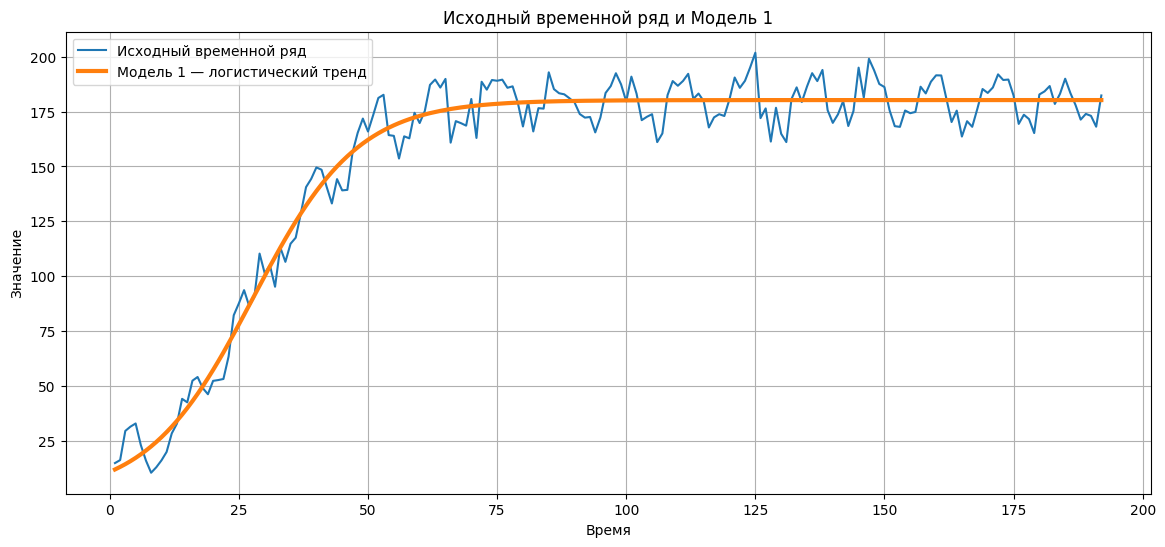

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df['t'], df['вар 1'], label='Исходный временной ряд')
plt.plot(
    df['t'],
    y_model1,
    linewidth=3,
    label='Модель 1 — логистический тренд'
)

plt.title('Исходный временной ряд и Модель 1')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(True)
plt.legend()

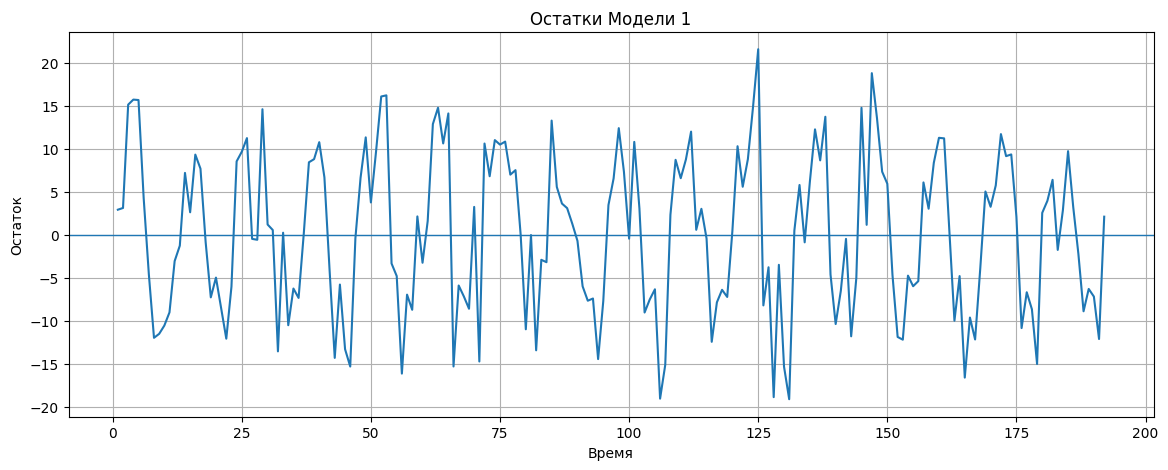

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(df['t'], resid1)
plt.axhline(0, linewidth=1)

plt.title('Остатки Модели 1')
plt.xlabel('Время')
plt.ylabel('Остаток')
plt.grid(True)

plt.show()

<Figure size 1400x500 with 0 Axes>

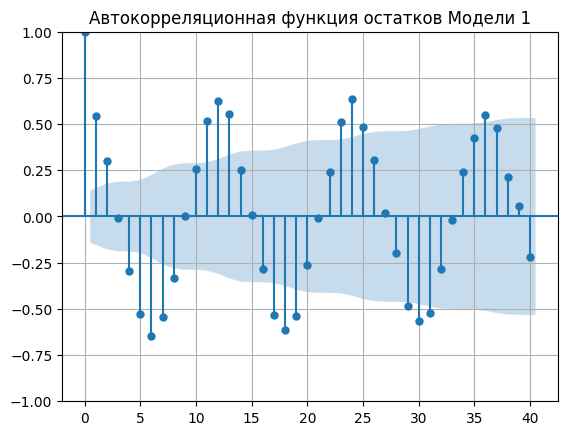

In [ ]:
lags = min(40, len(resid1) // 2 - 1)

plt.figure(figsize=(14, 5))
plot_acf(resid1, lags=lags)
plt.title('Автокорреляционная функция остатков Модели 1')
plt.grid(True)
plt.show()

ACF остатков также имеет выраженную периодическую структуру. Результаты теста Льюнга–Бокса подтверждают наличие статистически значимой автокорреляции: для лагов 12 и 24 значения \(p\)-value существенно меньше уровня значимости \(0.05\).
Следовательно, остатки Модели 1 не являются белым шумом. После выделения тренда в них сохраняется выраженная сезонная составляющая с периодом 12 наблюдений. Поэтому на следующем этапе необходимо дополнить трендовую модель сезонной компонентой.

<Figure size 1400x500 with 0 Axes>

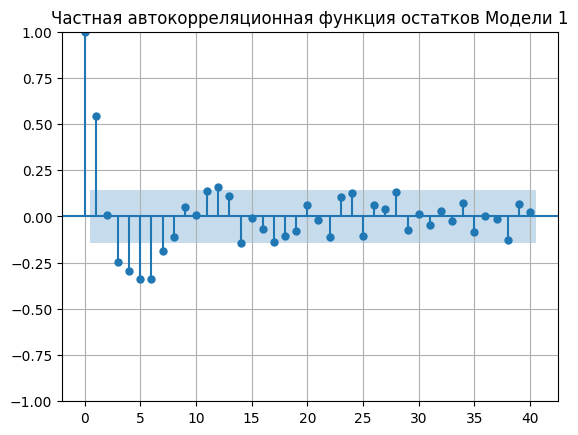

In [ ]:
plt.figure(figsize=(14, 5))
plot_pacf(
    resid1,
    lags=lags,
    method='ywm'
)

plt.title('Частная автокорреляционная функция остатков Модели 1')
plt.grid(True)
plt.show()

In [ ]:
ljung_box = acorr_ljungbox(
    resid1,
    lags=[12, 24],
    return_df=True
)

display(ljung_box)

,lb_stat,lb_pvalue
12,463.015124,1.624159e-91
24,935.361047,4.650823e-182


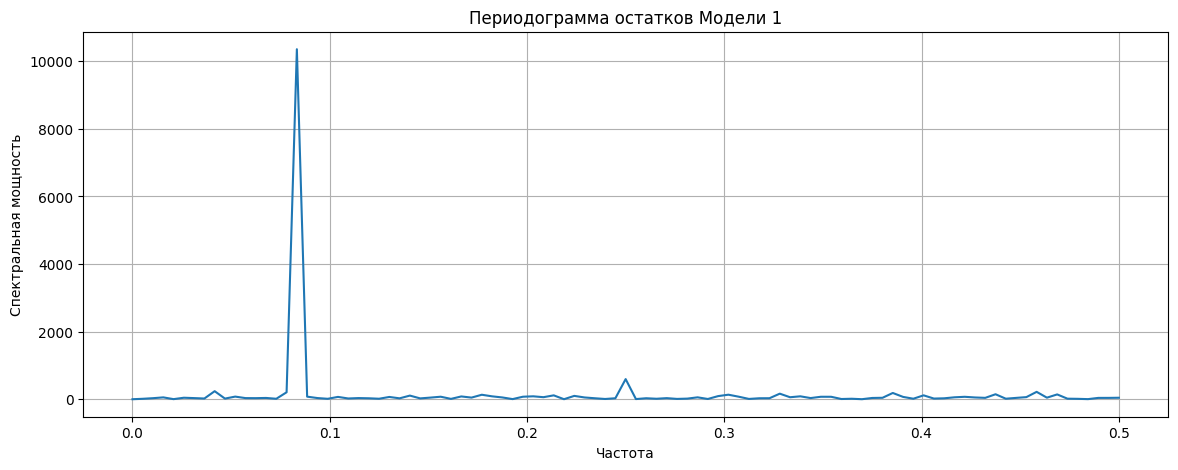

Основная частота: 0.0833
Оценка периода: 12.00


/tmp/ipykernel_12554/1140018385.py:18: RuntimeWarning: divide by zero encountered in divide
  periods = 1 / freq_nonzero


In [ ]:
freq, power = periodogram(resid1)

plt.figure(figsize=(14, 5))

plt.plot(freq, power)

plt.title('Периодограмма остатков Модели 1')
plt.xlabel('Частота')
plt.ylabel('Спектральная мощность')
plt.grid(True)

plt.show()

freq_nonzero = freq
power_nonzero = power

# Рассматриваем разумные периоды, например 2–30
periods = 1 / freq_nonzero

valid = (periods >= 2) & (periods <= 30)

freq_valid = freq_nonzero[valid]
power_valid = power_nonzero[valid]
periods_valid = periods[valid]

idx = np.argmax(power_valid)

main_freq = freq_valid[idx]
main_period = periods_valid[idx]

print(f'Основная частота: {main_freq:.4f}')
print(f'Оценка периода: {main_period:.2f}')

In [ ]:
def gompertz(t, K, A, B):
    return K * np.exp(-A * np.exp(-B * df['t']))

# Начальные значения параметров
p0 = [
    np.max(df['вар 1']),   # K
    5,           # A
    0.05         # B
]

params_g, cov_g = curve_fit(
    gompertz,
    df['t'],
    df['вар 1'],
    p0=p0,
    bounds=(0, np.inf),
    maxfev=50000
)

K, A, B = params_g

y_gompertz = gompertz(df['t'], *params_g)
resid_g = df['вар 1'] - y_gompertz

print(f"K = {K:.4f}")
print(f"A = {A:.4f}")
print(f"B = {B:.4f}")

print(
    f"T(t) = {K:.4f} * exp("
    f"-{A:.4f} * exp(-{B:.4f} * t))"
)

K = 181.1586
A = 4.3669
B = 0.0693
T(t) = 181.1586 * exp(-4.3669 * exp(-0.0693 * t))


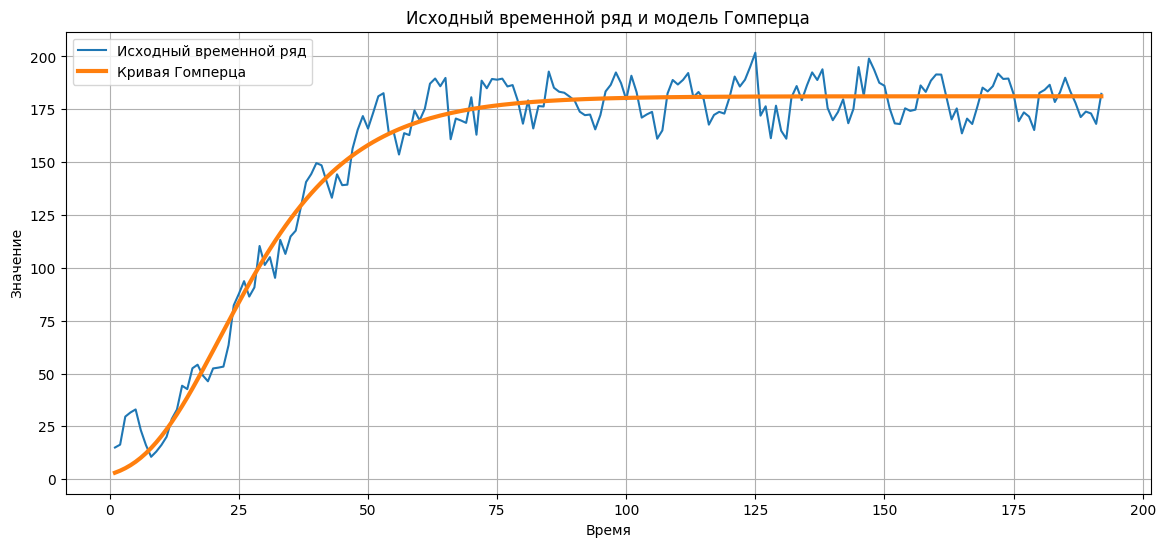

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df['t'], df['вар 1'], label='Исходный временной ряд')
plt.plot(
    df['t'],
    y_gompertz,
    linewidth=3,
    label='Кривая Гомперца'
)

plt.xlabel('Время')
plt.ylabel('Значение')
plt.title('Исходный временной ряд и модель Гомперца')
plt.grid(True)
plt.legend()

plt.show()

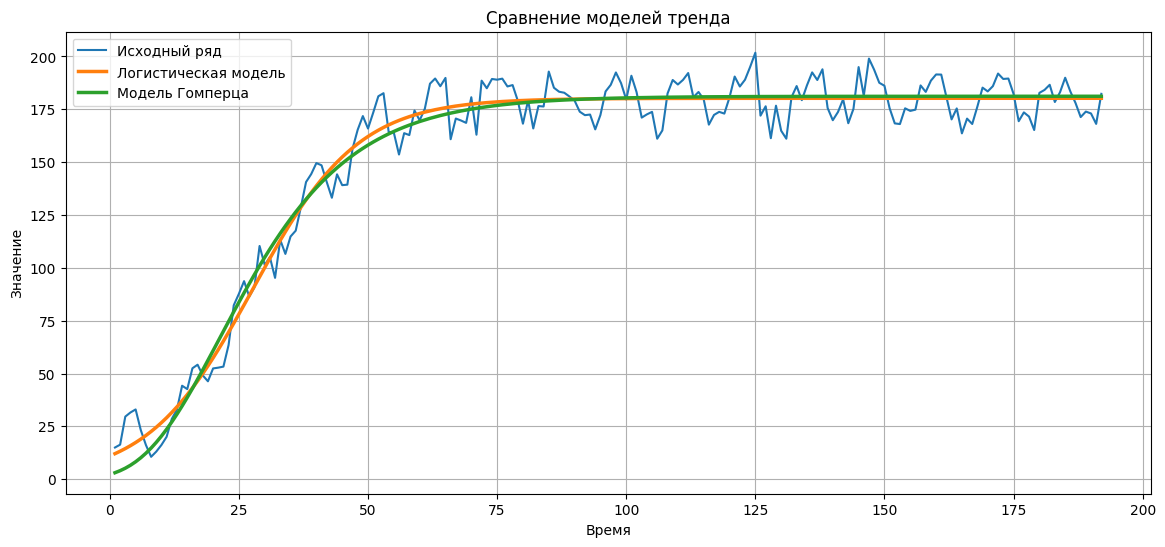

In [ ]:

plt.figure(figsize=(14, 6))

plt.plot(df['t'], df['вар 1'], label='Исходный ряд')
plt.plot(df['t'], y_model1, linewidth=2.5,
         label='Логистическая модель')
plt.plot(df['t'], y_gompertz, linewidth=2.5,
         label='Модель Гомперца')

plt.xlabel('Время')
plt.ylabel('Значение')
plt.title('Сравнение моделей тренда')
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
def metrics(y, y_hat):
    return {
        'R2': r2_score(y, y_hat),
        'RMSE': np.sqrt(mean_squared_error(y, y_hat)),
        'MAE': mean_absolute_error(y, y_hat),
        'SSE': np.sum((y - y_hat)**2)
    }

print('Логистическая:')
print(metrics(df['вар 1'], y_model1))

print('\nГомперц:')
print(metrics(df['вар 1'], y_gompertz))

Логистическая:
{'R2': 0.9664205966393097, 'RMSE': np.float64(9.130546065816034), 'MAE': 7.740980967845997, 'SSE': np.float64(16006.439320317822)}

Гомперц:
{'R2': 0.9616140181644761, 'RMSE': np.float64(9.762175051822473), 'MAE': 8.143720700963888, 'SSE': np.float64(18297.61185454562)}


#2.3.2


Анализ остатков Модели 1 показал наличие устойчивой сезонной составляющей с периодом \(P=12\). Поскольку амплитуда сезонных колебаний практически постоянна и не зависит от уровня ряда, используется аддитивная сезонная модель.

При параметрической идентификации одновременно уточняются параметры тренда и определяются коэффициенты сезонной составляющей.

In [ ]:
P1 = 12
P2 = 4

def model2(t, K, r, t0, a12, b12, a4, b4):

    trend = K / (
        1 + np.exp(-r * (t - t0))
    )

    seasonal12 = (
        a12 * np.cos(2 * np.pi * t / P1)
        + b12 * np.sin(2 * np.pi * t / P1)
    )

    seasonal4 = (
        a4 * np.cos(2 * np.pi * t / P2)
        + b4 * np.sin(2 * np.pi * t / P2)
    )

    return trend + seasonal12 + seasonal4

In [ ]:
P = 12
def model3(t, K, r, t0, a1, b1):
    trend = K / (1 + np.exp(-r * (t - t0)))

    seasonal1 = (
        a1 * np.cos(2 * np.pi * t / P)
        + b1 * np.sin(2 * np.pi * t / P)
    )

    return trend + seasonal1

In [ ]:
p0_model2 = [
    K,      # начальное K
    r,      # начальное r
    t0,     # начальное t0

    -1.5,   # a12
    10.0,   # b12

    0.0,    # a4
    2.5     # b4
]

In [ ]:


p0_model3 = [
    K,      # из Модели 1
    r,      # из Модели 1
    t0,     # из Модели 1
    10,     # начальный a1
    0       # начальный
]

In [ ]:
params2, cov2 = curve_fit(
    model2,
    df["t"],
    df["вар 1"],
    p0=p0_model2,

    bounds=(
        [
            150, 0.001, 0,
            -50, -50,
            -50, -50
        ],
        [
            250, 1.0, 100,
            50, 50,
            50, 50
        ]
    ),

    maxfev=100000
)

(
    K2,
    r2,
    t02,
    a12,
    b12,
    a4,
    b4
)  = params2

In [ ]:
params3, cov3 = curve_fit(
    model3,
    df['t'],
    df['вар 1'],
    p0=p0_model3,

    bounds=(
        [150, 0.001, 0,   -50, -50],
        [250, 1.000, 100,  50,  50]
    ),

    maxfev=100000
)

K2_3, r2_3, t02_3, a1_3, b1_3 = params3

print(f'K  = {K2_3:.6f}')
print(f'r  = {r2_3:.6f}')
print(f't0 = {t02_3:.6f}')
print(f'a1 = {a1_3:.6f}')
print(f'b1 = {b1_3:.6f}')

K  = 180.320608
r  = 0.099235
t0 = 27.785680
a1 = -1.492310
b1 = 10.286155


В результате параметрической идентификации получены значения
K=180.3206,
r=0.099235,
t_0=27.7857,
a_1=-1.4923,
b_1=10.2862.

In [ ]:
y_model2 = model2(df['t'], *params2)
y_model3 = model3(df['t'], *params3)
resid2 = df['вар 1'] - y_model2
resid3 = df['вар 1'] - y_model3

In [ ]:
print(
    f"y(t) = {K2_3:.4f} / "
    f"(1 + exp(-{r2_3:.4f} * (t - {t02_3:.4f}))) "
    f"+ ({a1_3:.4f}) * cos(2*pi*t/12) "
    f"+ ({b1_3:.4f}) * sin(2*pi*t/12)"
)

y(t) = 180.3206 / (1 + exp(-0.0992 * (t - 27.7857))) + (-1.4923) * cos(2*pi*t/12) + (10.2862) * sin(2*pi*t/12)


In [ ]:
A12 = np.sqrt(
    a12**2 + b12**2
)

A4 = np.sqrt(
    a4**2 + b4**2
)

print("A12 =", A12)
print("A4  =", A4)

A12 = 10.394242414195515
A4  = 2.492161640291057


In [ ]:
season_amplitude_3 = np.sqrt(a1_3**2 + b1_3**2)

print(
    f'Амплитуда сезонных колебаний = '
    f'{season_amplitude_3:.4f}'
)

Амплитуда сезонных колебаний = 10.3938


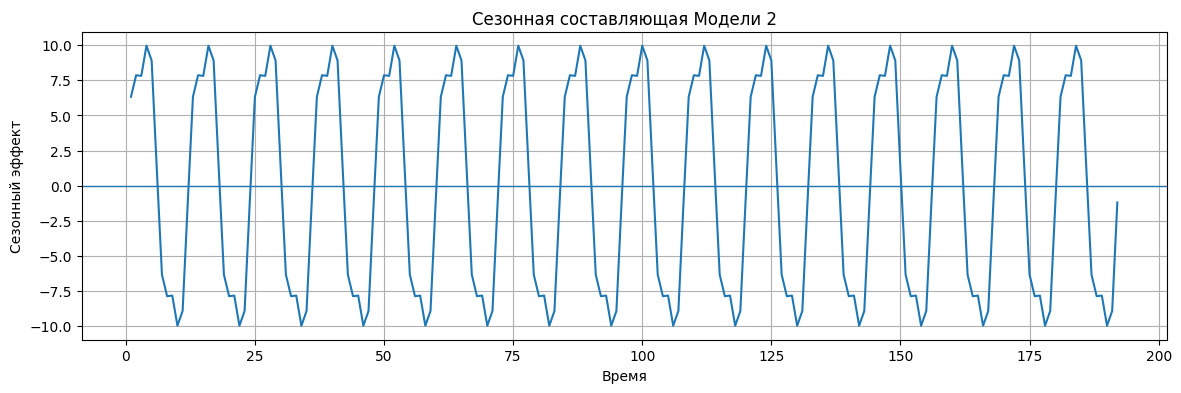

In [ ]:
seasonal2 = (
    a12 * np.cos(2 * np.pi * df['t'] / 12)
    + b12 * np.sin(2 * np.pi * df['t'] / 12)
    + a4 * np.cos(2 * np.pi * df['t'] / 4)
    + b4 * np.sin(2 * np.pi * df['t'] / 4)
)

plt.figure(figsize=(14, 4))
plt.plot(df['t'], seasonal2)
plt.axhline(0, linewidth=1)

plt.title('Сезонная составляющая Модели 2')
plt.xlabel('Время')
plt.ylabel('Сезонный эффект')
plt.grid(True)

plt.show()

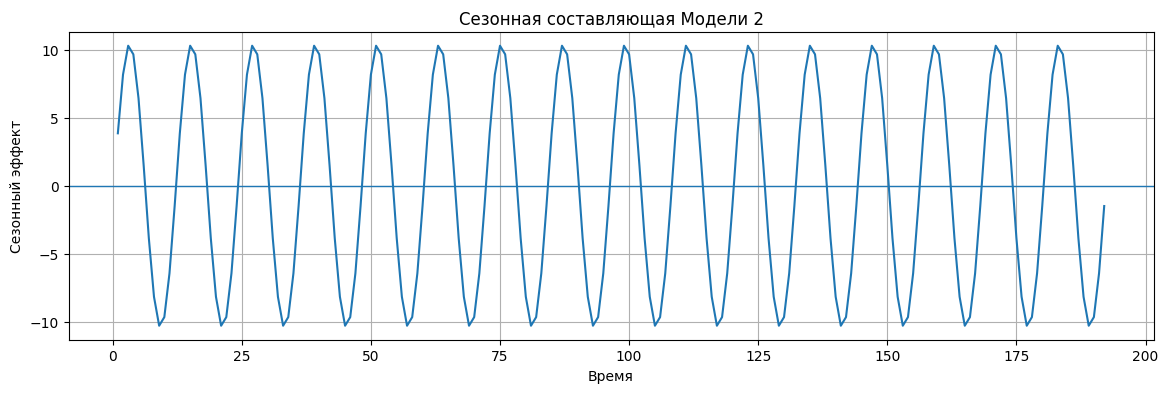

In [ ]:
seasonal3 = (
    a1_3 * np.cos(2 * np.pi * df['t'] / 12)
    + b1_3 * np.sin(2 * np.pi * df['t'] / 12)
)

plt.figure(figsize=(14, 4))
plt.plot(df['t'], seasonal3)
plt.axhline(0, linewidth=1)

plt.title('Сезонная составляющая Модели 2')
plt.xlabel('Время')
plt.ylabel('Сезонный эффект')
plt.grid(True)

plt.show()

In [ ]:
def model_metrics(y, y_hat):
    errors = y - y_hat

    return {
        'Минимальный остаток': np.min(errors),
        'Максимальный остаток': np.max(errors),
        'Средняя ошибка (ME)': np.mean(errors),
        'СКО ошибки': np.std(errors, ddof=1),
        'MAE': np.mean(np.abs(errors)),
        'MPE, %': np.mean(errors / y) * 100,
        'MAPE, %': np.mean(
            np.abs(errors / y)
        ) * 100,
        'RMSE': np.sqrt(np.mean(errors**2)),
        'R²': r2_score(y, y_hat)
    }

In [ ]:
metrics1 = model_metrics(df['вар 1'], y_model1)
metrics2 = model_metrics(df['вар 1'], y_model2)
metrics3 = model_metrics(df['вар 1'], y_model3)
table2 = pd.DataFrame({
    'Модель 1': metrics1,
    'Модель 2': metrics2,
    'Модель 3': metrics3
})

display(table2)

,Модель 1,Модель 2,Модель 3
Минимальный остаток,-19.111846,-16.703461,-16.995612
Максимальный остаток,21.561621,13.007914,15.013039
Средняя ошибка (ME),0.085795,0.023434,0.026733
СКО ошибки,9.154013,5.140201,5.435355
MAE,7.740981,3.979456,4.271212
"MPE, %",-0.985218,-0.307971,-0.278974
"MAPE, %",7.691282,3.636097,3.651078
RMSE,9.130546,5.126851,5.421248
R²,0.966421,0.989413,0.988162


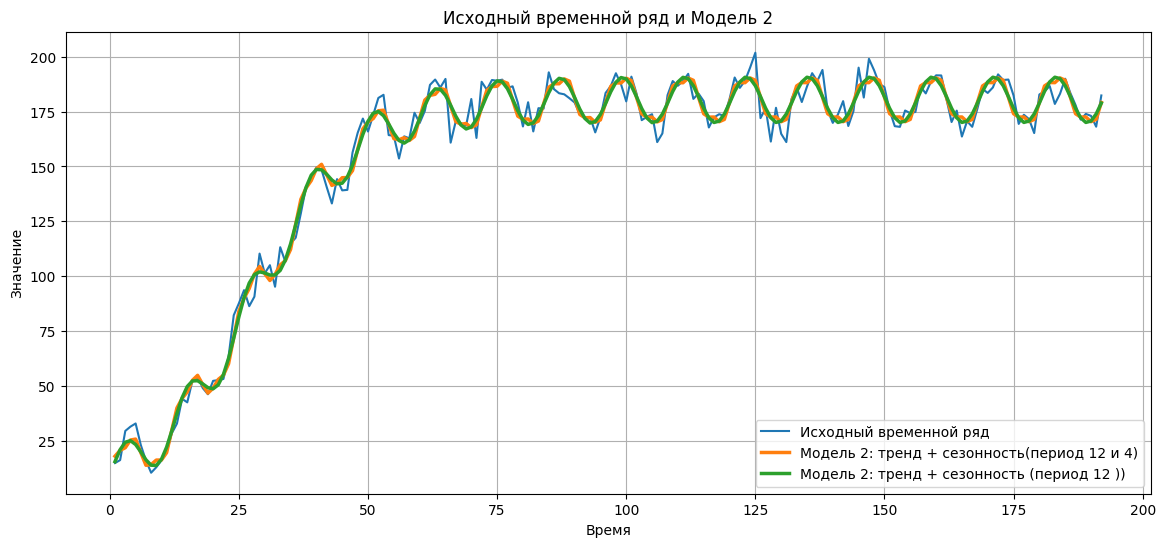

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df['t'],
    df['вар 1'],
    label='Исходный временной ряд'
)

plt.plot(
    df['t'],
    y_model2,
    linewidth=2.5,
    label='Модель 2: тренд + сезонность(период 12 и 4)'
)

plt.plot(
    df['t'],
    y_model3,
    linewidth=2.5,
    label='Модель 2: тренд + сезонность (период 12 ))'
)

plt.xlabel('Время')
plt.ylabel('Значение')
plt.title('Исходный временной ряд и Модель 2')
plt.grid(True)
plt.legend()

plt.show()

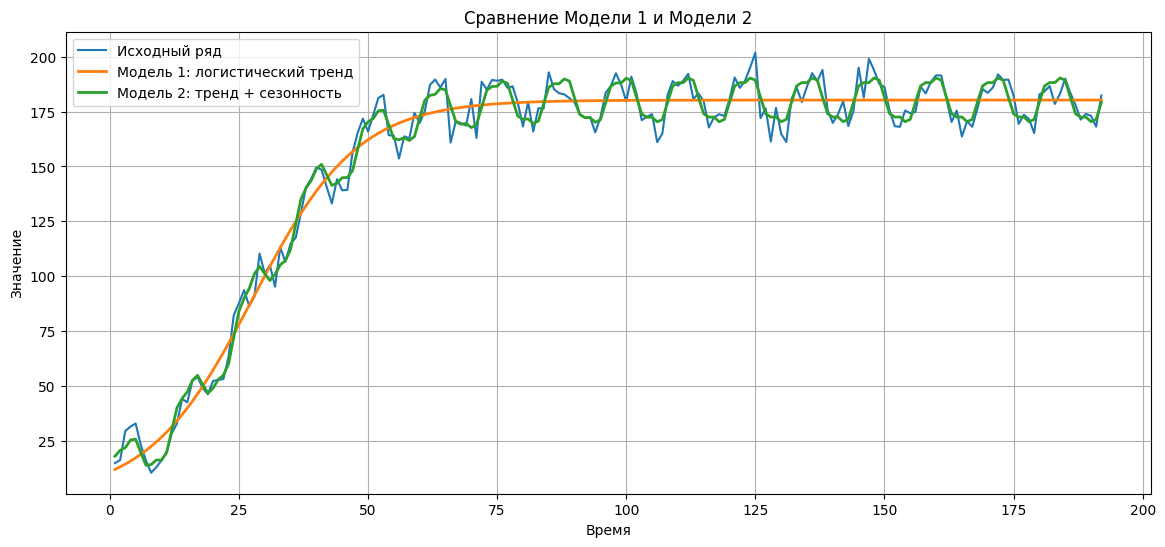

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df['t'], df['вар 1'], label='Исходный ряд')

plt.plot(
    df['t'],
    y_model1,
    linewidth=2,
    label='Модель 1: логистический тренд'
)

plt.plot(
    df['t'],
    y_model2,
    linewidth=2,
    label='Модель 2: тренд + сезонность'
)

plt.xlabel('Время')
plt.ylabel('Значение')
plt.title('Сравнение Модели 1 и Модели 2')
plt.grid(True)
plt.legend()

plt.show()

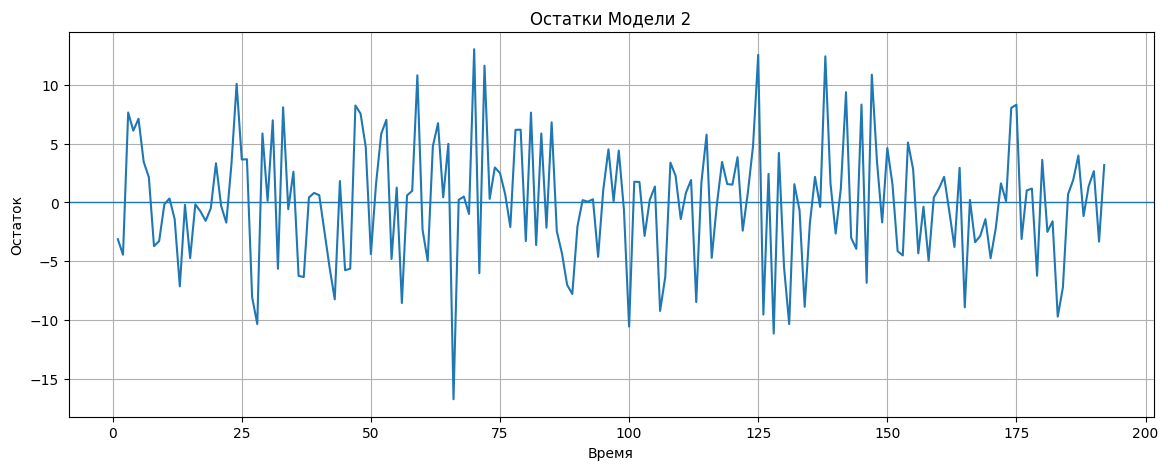

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(df['t'], resid2)
plt.axhline(0, linewidth=1)

plt.xlabel('Время')
plt.ylabel('Остаток')
plt.title('Остатки Модели 2')
plt.grid(True)

plt.show()

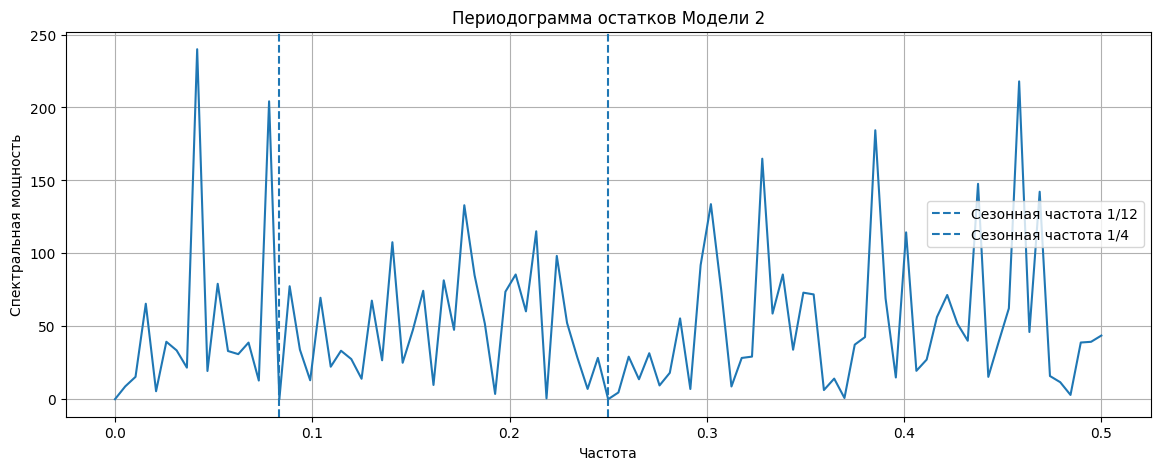

In [ ]:
freq2, power2 = periodogram(resid2)

plt.figure(figsize=(14, 5))

plt.plot(freq2, power2)

plt.axvline(
    1 / 12,
    linestyle='--',
    label='Сезонная частота 1/12'
)

plt.axvline(
    1 / 4,
    linestyle='--',
    label='Сезонная частота 1/4'
)

plt.xlabel('Частота')
plt.ylabel('Спектральная мощность')
plt.title('Периодограмма остатков Модели 2')
plt.grid(True)
plt.legend()

plt.show()

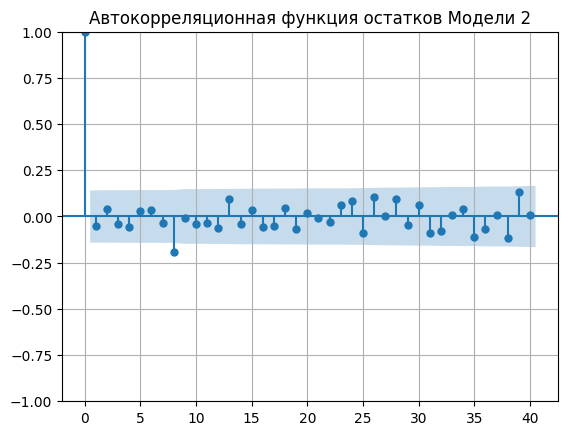

In [ ]:
lags = min(40, len(resid2) // 2 - 1)

plot_acf(
    resid2,
    lags=lags
)

plt.title(
    'Автокорреляционная функция остатков Модели 2'
)
plt.grid(True)
plt.show()

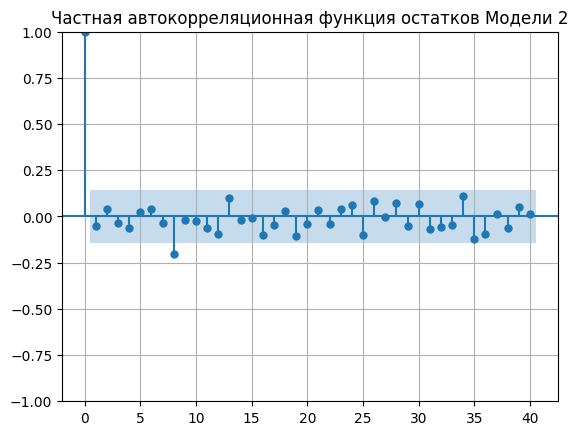

In [ ]:
plot_pacf(
    resid2,
    lags=lags,
    method='ywm'
)

plt.title(
    'Частная автокорреляционная функция остатков Модели 2'
)

plt.grid(True)
plt.show()

In [ ]:
ljung2 = acorr_ljungbox(
    resid2,
    lags=[12, 24],
    return_df=True
)

display(ljung2)

,lb_stat,lb_pvalue
12,11.056353,0.524096
24,18.723628,0.766563


После включения сезонной составляющей точность модели существенно увеличилась. Коэффициент детерминации повысился с \(R^2=0.9664\) для Модели 1 до \(R^2=0.9882\) для Модели 2. RMSE уменьшилась с \(9.1305\) до \(5.4212\), MAE — с \(7.7410\) до \(4.2712\)

Таким образом, добавление сезонной составляющей существенно повысило точность описания временного ряда.
Остатки Модели 2 колеблются около нулевого уровня и не содержат визуально выраженного тренда. Основной сезонный пик с периодом 12, наблюдавшийся в остатках Модели 1, после включения гармонической составляющей устранён. На периодограмме остаются отдельные спектральные максимумы, однако ACF и PACF не демонстрируют устойчивой статистически значимой корреляционной структуры.
По тесту Льюнга–Бокса получены \(p\)-value \(0.706\) для лага 12 и \(0.195\) для лага 24. Оба значения превышают уровень значимости \(\alpha=0.05\), поэтому гипотеза об отсутствии автокорреляции не отвергается.
Следовательно, Модель 2 адекватно описывает основные детерминированные составляющие исследуемого временного ряда — тренд и сезонность.

#2.3.3

In [ ]:
ljung2 = acorr_ljungbox(
    resid2,
    lags=[6, 12, 18, 24],
    return_df=True
)

display(ljung2)

,lb_stat,lb_pvalue
6,2.127870,0.907571
12,11.056353,0.524096
18,15.129685,0.653044
24,18.723628,0.766563


После идентификации трендовой и сезонной составляющих был выполнен анализ остатков Модели 2 с целью выявления возможной авторегрессионной структуры.  
Анализ автокорреляционной функции остатков показал, что большинство коэффициентов автокорреляции находится в пределах доверительного интервала. Характерного для авторегрессионного процесса систематического затухания ACF не наблюдается. Частная автокорреляционная функция также не демонстрирует последовательности статистически значимых коэффициентов, позволяющей выделить авторегрессионную составляющую определённого порядка.
Дополнительно был выполнен тест Льюнга–Бокса для лагов 6, 12, 18 и 24. Полученные значения \(p\)-value составили соответственно \(0.756\), \(0.706\), \(0.599\) и \(0.195\). Все значения превышают уровень значимости \(\alpha=0.05\), поэтому нулевая гипотеза об отсутствии автокорреляции остатков не отвергается.Поэтому построение Модели 3 не требуется

#Вывод

В ходе лабораторной работы был исследован временной ряд, содержащий 192 ежемесячных наблюдения. На этапе предварительного анализа установлено, что ряд имеет выраженный нелинейный тренд с насыщением и сезонную составляющую с периодом 12 наблюдений. Амплитуда сезонных колебаний практически постоянна, что позволило использовать аддитивное представление временного ряда.
Методом последовательной идентификации сначала была определена трендовая составляющая. В качестве Модели 1 выбрана логистическая функция, описывающая рост с последующим выходом на горизонтальную асимптоту около 180 единиц. Полученная модель характеризуется коэффициентом детерминации \(R^2=0.9664\), RMSE \(=9.1305\), MAE \(=7.7410\) и MAPE \(=7.6913\%\).
Анализ остатков Модели 1 выявил выраженную периодическую структуру с периодом 12 наблюдений. Поэтому в модель была включена гармоническая сезонная составляющая. Полученная Модель 2, включающая логистический тренд и сезонность, имеет существенно более высокую точность: \(R^2=0.9882\), RMSE \(=5.4212\), MAE \(=4.2712\), MAPE \(=3.6511\%\).
После выделения тренда и сезонности статистически значимой автокорреляционной структуры в остатках не обнаружено. По тесту Льюнга–Бокса значения \(p\)-value для лагов 6, 12, 18 и 24 превышают уровень значимости \(0.05\). Поэтому авторегрессионная составляющая не выделяется и необходимость построения Модели 3 отсутствует.
Таким образом, последовательная идентификация завершена на Модели 2. Итоговая модель включает нелинейный логистический тренд и аддитивную гармоническую сезонную составляющую с периодом 12 и адекватно описывает основную структуру исследуемого временного ряда.

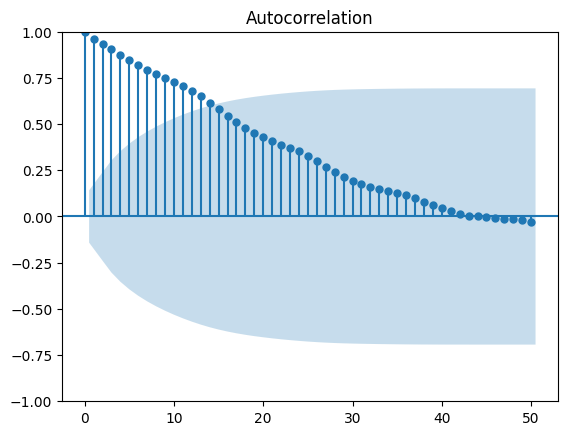

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(df['вар 1'], lags=50) # lags - сколько шагов назад проверять
plt.show()